# TP 3 (Predicion Lineal)

## Imports

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import resample_poly, correlate, lfilter, freqz
from scipy.linalg import solve_toeplitz, toeplitz
from matplotlib.ticker import MultipleLocator

# Parte 1 (Grabaciones)


El primer ejercicio consiste únicamente en preparar correctamente las señales que se utilizarán después. Se graban los sonidos /a/, /y/ y /sh/ con una frecuencia de muestreo de 16 kHz y se selecciona un fragmento de 1 s de cada grabación.

$$f_s = 16\ \text{kHz} = 16\,000\ \text{muestras/s}$$

Por tanto, un segundo de señal contiene 16 000 muestras. Trabajar con la misma duración y la misma frecuencia de muestreo permite comparar los tres sonidos en las mismas condiciones.

En el caso de /a/ se pide mantener el tono lo más estable posible. La razón es que /a/ es un sonido sonoro: las cuerdas vocales vibran de forma aproximadamente periódica. Si el tono cambia mucho durante el segundo analizado, también cambia el periodo de esa repetición y resulta más difícil identificarla en los ejercicios posteriores.

| Sonido | Tipo aproximado   | Qué esperamos                               |
|:------:|:-----------------:|:-------------------------------------------:|
| /a/    | Sonoro y periódico | Estructura de corto plazo + periodicidad de pitch |
| /y/    | Sonoro            | Estructura espectral y periodicidad         |
| /sh/   | No sonoro         | Comportamiento más parecido a ruido filtrado |

In [14]:
# FUNCIÓN PARA LEER EL AUDIO

def cargar_audio(nombre, duracion=1):

    fs, x = wavfile.read(nombre)

    # Si es estéreo, lo pasamos a mono
    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x.astype(float)

    # Si no está a 16 kHz, lo remuestreamos
    if fs != 16000:

        x = resample_poly(x,16000,fs)
        fs = 16000

    # solo limita el audio si es especificado
    if duracion is not None:
        x = x[:16000 * duracion]

    # Quitamos la media
    x = x - np.mean(x)

    # Normalizamos
    x = x / np.max(np.abs(x))

    return x

# Parte 2 (Predicción forward y MSE mínimo $J(M)$)

En este apartado se utiliza la predicción lineal forward. La idea es que, en lugar de mirar la señal completa, intentamos predecir cada muestra actual $x[n]$ a partir de las muestras inmediatamente anteriores. Si usamos un predictor de orden $M$, utilizamos las $M$ muestras anteriores para construir la predicción.

$$\hat{x}[n] = a_1 x[n-1] + a_2 x[n-2] + \cdots + a_M x[n-M]$$

Aquí $x[n]$ es la muestra real, $\hat{x}[n]$ es la muestra predicha, $M$ indica cuántas muestras pasadas utilizamos y $a_1, a_2, \dots, a_M$ son los coeficientes del predictor.

Por ejemplo, para $M = 2$ sólo usamos $x[n-1]$ y $x[n-2]$; para $M = 20$ usamos las veinte muestras anteriores.

Los coeficientes $a_1, a_2, \dots, a_M$ no se eligen a mano. Se calculan a partir de la propia señal para que el error de predicción sea lo más pequeño posible. Para ello el código estudia cuánto se parece la señal a versiones retrasadas de sí misma mediante la autocorrelación.

La autocorrelación $r_x[k]$ mide, de forma simplificada, cuánto se parece $x[n]$ a $x[n-k]$. Por ejemplo, $r_x[1]$ mide la relación con la muestra anterior, $r_x[10]$ con una muestra situada diez posiciones atrás, etc. Esta información es la que permite determinar qué peso debe tener cada muestra pasada en la predicción.

A partir de estas correlaciones se construye el sistema de ecuaciones $\mathbf{R}\,\mathbf{a} = \mathbf{p}$. El vector $\mathbf{a}$ contiene los coeficientes $[a_1, a_2, \dots, a_M]^T$. Resolver este sistema proporciona los coeficientes óptimos, es decir, los que minimizan el error cuadrático medio para ese valor de $M$.

Una vez obtenida la predicción, se calcula el error forward como la diferencia entre la muestra real y la predicha:

$$e_f[n] = x[n] - \hat{x}[n]$$

Si el predictor acierta, $\hat{x}[n]$ será muy parecida a $x[n]$ y $e_f[n]$ será pequeño. Para resumir el error de toda la señal en un único número se calcula el error cuadrático medio (MSE), que en el enunciado se denomina $J(M)$:

$$J(M) = \frac{1}{N} \sum_n e_f^2[n]$$

Por tanto, para cada valor de $M$ el procedimiento es siempre el mismo:

Se calcula la autocorrelación de la señal, se obtienen los coeficientes óptimos $a_1, \dots, a_M$, se forma la predicción $\hat{x}[n]$, se obtiene el error $e_f[n]$ y finalmente se calcula $J(M)$.

Después se repite todo el proceso para $M = 1, 2, 3, \dots$ y se representa $J$ frente a $M$.

## Qué hace el código con los audios antes de calcular $J(M)$

1. Lee el archivo WAV y obtiene la frecuencia de muestreo y las muestras $x[n]$.
2. Si el archivo tiene dos canales, se pasa a mono, ya que para este análisis sólo se necesita una señal.
3. Si la grabación no está a 16 kHz, se remuestrea a $f_s = 16$ kHz, tal como exige el enunciado.
4. Se selecciona un segundo de señal. A 16 kHz esto corresponde a 16 000 muestras.
5. Se elimina la media y se normaliza la amplitud. Esto centra la señal alrededor de cero y evita que diferencias de escala entre grabaciones afecten a la comparación.
6. Con la señal ya preparada se calcula la autocorrelación $r_x[k]$. A partir de ella se construyen $\mathbf{R}$ y $\mathbf{p}$ y se resuelve $\mathbf{R}\,\mathbf{a} = \mathbf{p}$ para obtener los coeficientes del predictor.
7. Finalmente se calcula el MSE mínimo $J(M)$. El código repite este cálculo para muchos valores de $M$, por lo que al final obtenemos una curva $J(M)$.

En general, al aumentar $M$ el predictor dispone de más información del pasado y $J(M)$ disminuye. Sin embargo, llega un momento en el que añadir más muestras anteriores apenas mejora la predicción. Esa transición es la que se observa mediante los llamados codos de la curva.

## Qué significa un "codo"

Un codo es una zona donde cambia claramente la pendiente de $J(M)$. Antes del codo, aumentar $M$ reduce bastante el error. Después del codo, el beneficio de seguir aumentando $M$ es mucho menor. El codo indica que el predictor acaba de capturar una estructura importante de la señal.

In [15]:
# FUNCIÓN PARA CALCULAR J(M)

def calcular_J(x, Mmax):

    N = len(x)

    # Autocorrelación
    r = correlate( x, x, mode="full", method="fft")

    centro = N - 1

    r = r[centro:centro + Mmax + 1] / N
    valores_J = []


    for M in range(1, Mmax + 1):
        p = r[1:M+1]
        a = solve_toeplitz((r[:M], r[:M]),p)

        # MSE mínimo
        J = r[0] - np.dot(p, a)

        valores_J.append(J)


    return np.array(valores_J)

C:\Users\itoma\AppData\Local\Temp\ipykernel_23512\1087720810.py:5: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, x = wavfile.read(nombre)


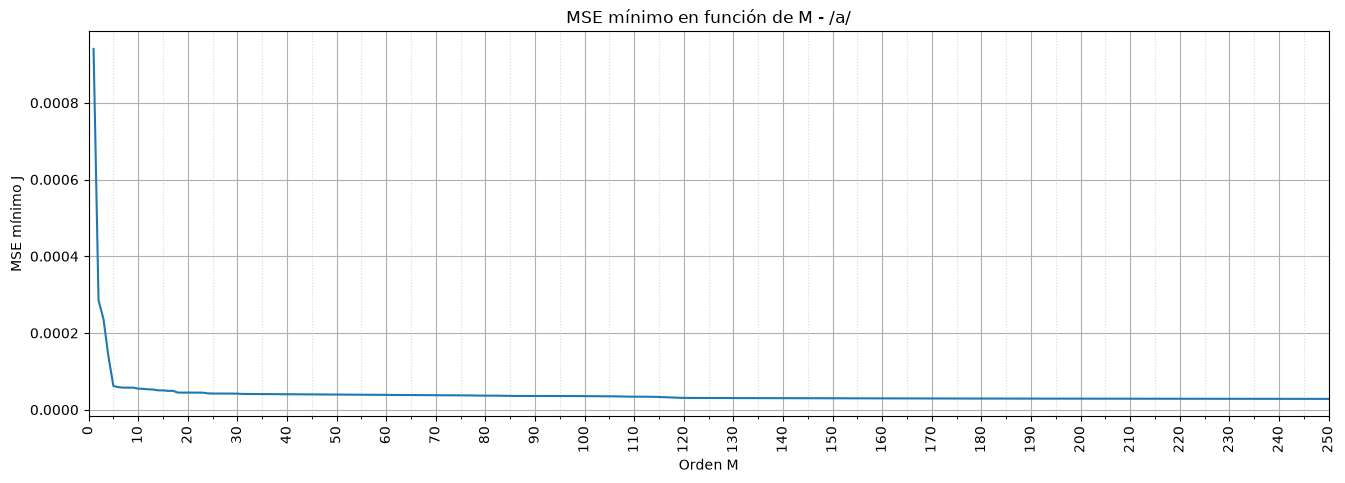

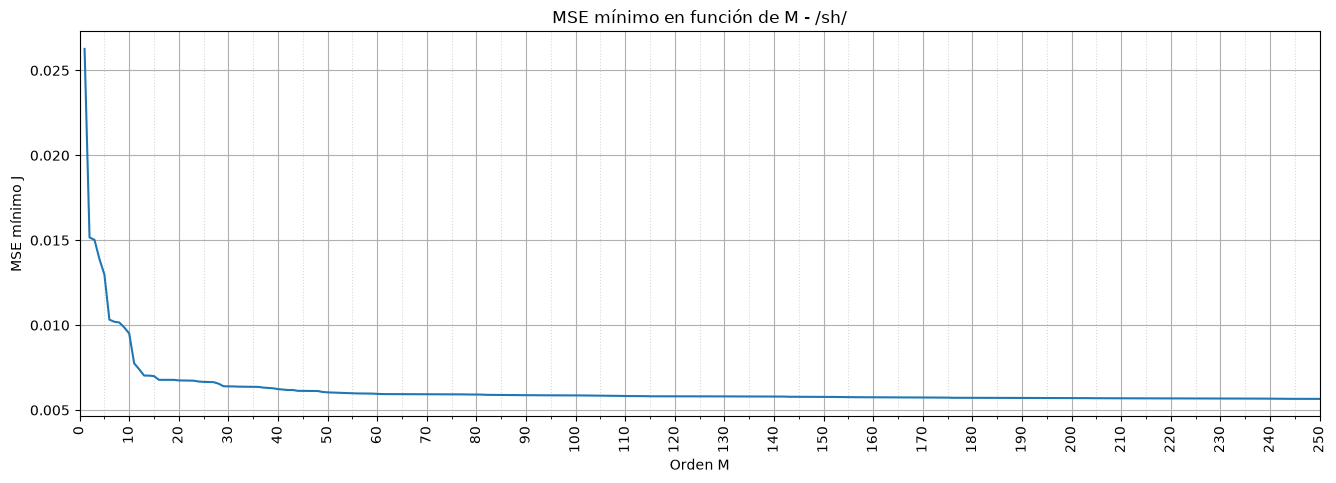

In [ ]:
# CARGAR /a/ Y /sh/
a = cargar_audio("a_16k.wav", duracion=None)
sh = cargar_audio("sh_16k.wav", duracion=None)


# CALCULAR J(M)
Mmax = 250

J_a = calcular_J(a,Mmax)
J_sh = calcular_J(sh,Mmax)

M = np.arange( 1, Mmax + 1)

# GRÁFICA /a/
fig, ax = plt.subplots(figsize=(16,5))
ax.plot(M,J_a)
ax.set_xlabel("Orden M")
ax.set_ylabel("MSE mínimo J")
ax.set_title( "MSE mínimo en función de M - /a/")
ax.set_xlim(0, Mmax)
ax.xaxis.set_major_locator(MultipleLocator(10))   # marca cada 10
ax.xaxis.set_minor_locator(MultipleLocator(5))    # marca menor cada 5
ax.grid(which="major")
ax.grid(which="minor", linestyle=":", alpha=0.5)
plt.xticks(rotation=90)
plt.show()

# GRÁFICA /sh/
fig, ax = plt.subplots(figsize=(16,5))
ax.plot(M, J_sh)
ax.set_xlabel("Orden M")
ax.set_ylabel("MSE mínimo J")
ax.set_title("MSE mínimo en función de M - /sh/")
ax.set_xlim(0, Mmax)
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_minor_locator(MultipleLocator(5))
ax.grid(which="major")
ax.grid(which="minor", linestyle=":", alpha=0.5)
plt.xticks(rotation=90)
plt.show()

## Graficando la señal de error pero en dB para pode ver los dos codos

En el gráfico anterior, no se pueden ver los dos picos de a, debido a que el grafico estaba dominado por la primera caida y como el segundo "codo" tiene una reducion de error mas minimo no se podía ver. Entoncés, graficamos el error de a pero esta vez en dB para poder ver los dos picos mas claramente. Ahora, en los graficos nuevos se puede ver que la señal de error para la grabacion de "a" claramente tiene otro codo alrededor de m = 110-120. En cambio, fijandote en el zoom de "sh" se puede ver como no hay ningun otro codo, sino que el error simplemente decae.

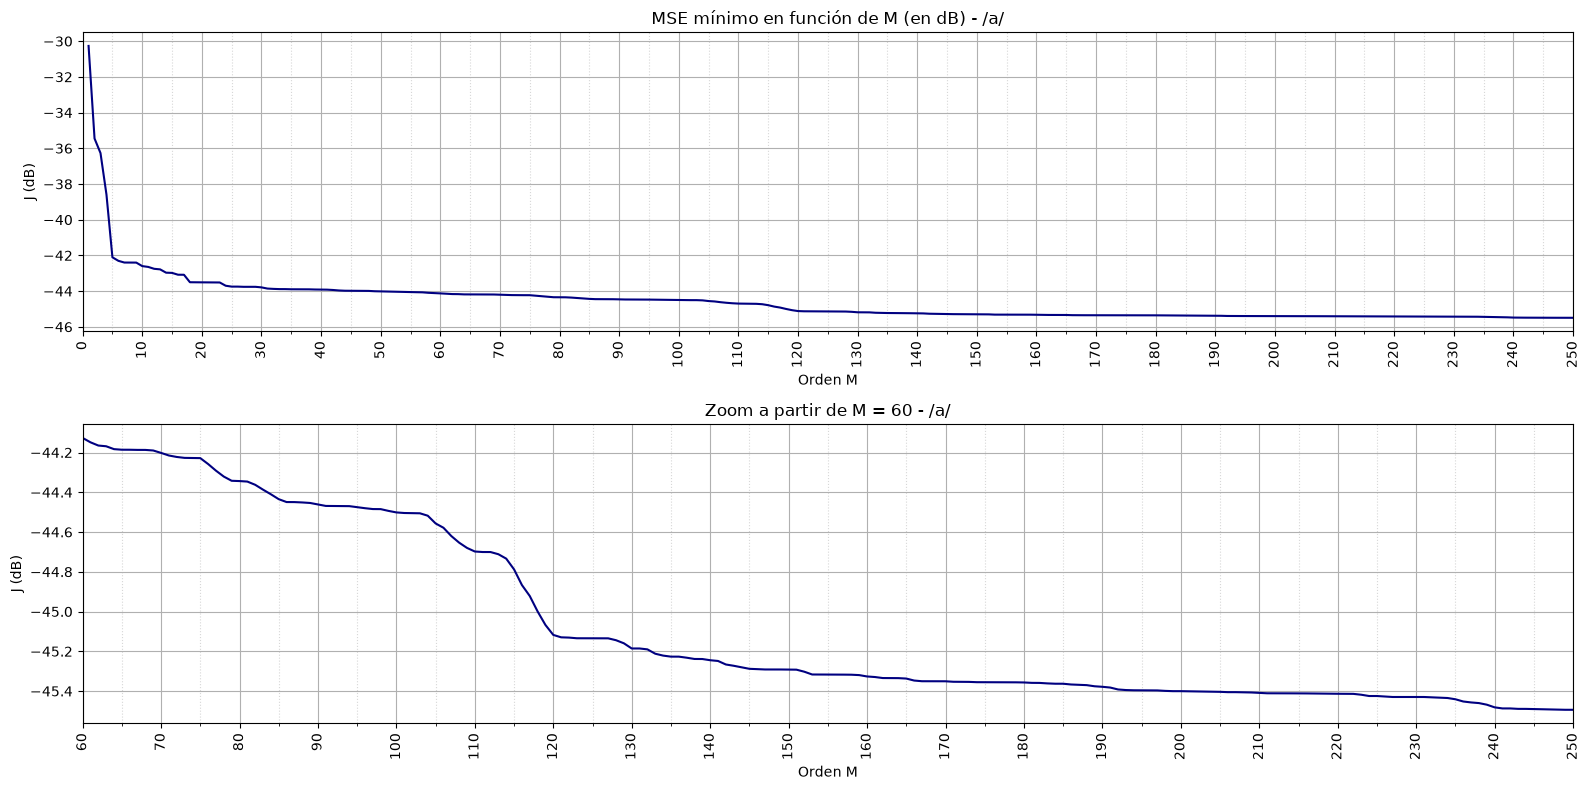

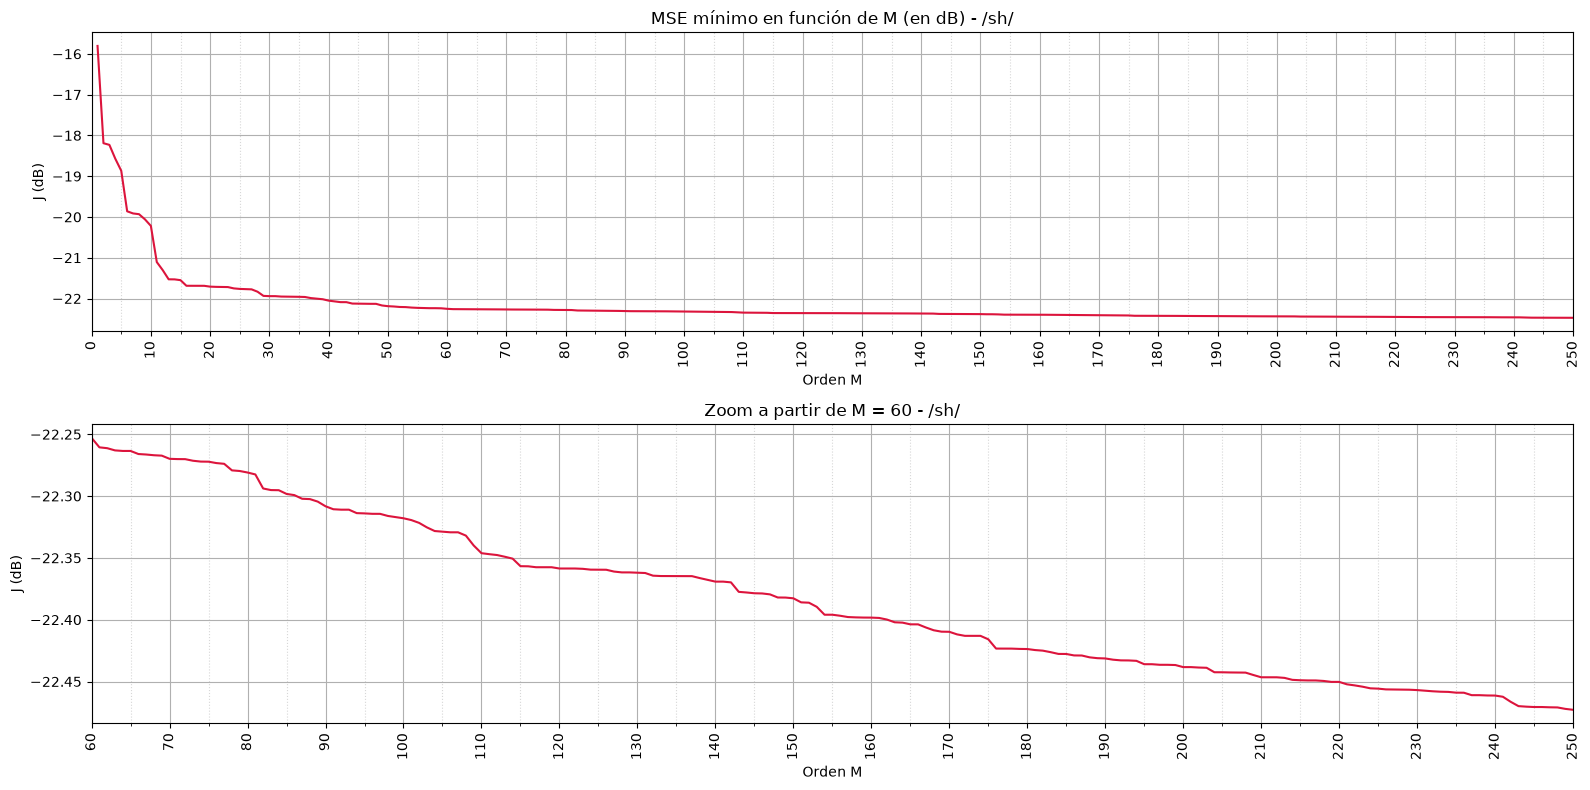

In [26]:
# J(M) EN dB PARA /a/ Y /sh/
J_a_dB = 10*np.log10(J_a)
J_sh_dB = 10*np.log10(J_sh)

def graficar_J_dB(M, J_dB, nombre, color, zoom_desde=60):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16,8))

    # Rango completo
    ax1.plot(M, J_dB, color=color)
    ax1.set_title(f"MSE mínimo en función de M (en dB) - {nombre}")
    ax1.set_ylabel("J (dB)")
    ax1.set_xlim(0, Mmax)

    # Zoom en la zona de M grandes (el eje y se ajusta solo a estos datos)
    zona = (M >= zoom_desde)
    ax2.plot(M[zona], J_dB[zona], color=color)
    ax2.set_title(f"Zoom a partir de M = {zoom_desde} - {nombre}")
    ax2.set_ylabel("J (dB)")
    ax2.set_xlim(zoom_desde, Mmax)

    for ax in (ax1, ax2):
        ax.set_xlabel("Orden M")
        ax.xaxis.set_major_locator(MultipleLocator(10))
        ax.xaxis.set_minor_locator(MultipleLocator(5))
        ax.grid(which="major")
        ax.grid(which="minor", linestyle=":", alpha=0.5)
        ax.tick_params(axis="x", rotation=90)

    plt.tight_layout()
    plt.show()

graficar_J_dB(M, J_a_dB, "/a/", "navy")
graficar_J_dB(M, J_sh_dB, "/sh/", "crimson")

## Investigando la señal de error $e^f(n)$

La primera parte es crear una función de error que te genere la señal de error, tomando como entrada una señal y el orden del filtro que vas a analizar.

In [5]:
def calcular_señal_de_error(x, M):

    N = len(x)
    r = correlate(x, x, mode="full", method="fft")

    centro = N - 1

    #estableciendo las matricies con lags positivos 
    r = r[centro:centro + M + 1] / N
    p = r[1:M+1]

    a = solve_toeplitz(r[:M],p)

    #creando la señal de error
    filtro_error = np.concatenate(([1], -a))
    e = lfilter(filtro_error, [1], x)

    return e

Ahora aplicando esta funcion de error forward para calcular los errores de la señal de ruido /a/ y /sh/. Esto esta hecho para intentar justificar porque hay dos codos en vez de uno (como dice la recomendacion en la consigna). Lo primero que hicimos es que nos fijamos en la señal de error en diferentes valores de M para ver como la señal de error cambiaba dependiendo de si estabamos en el primer, segundo codo, etc. Para encontrar estos valores de M nos fijamos en los graficos que creamos anteriroemnte, adnode utilizamos un python tool para que sean mas precisos y se pueda leer mejor el valor de M.

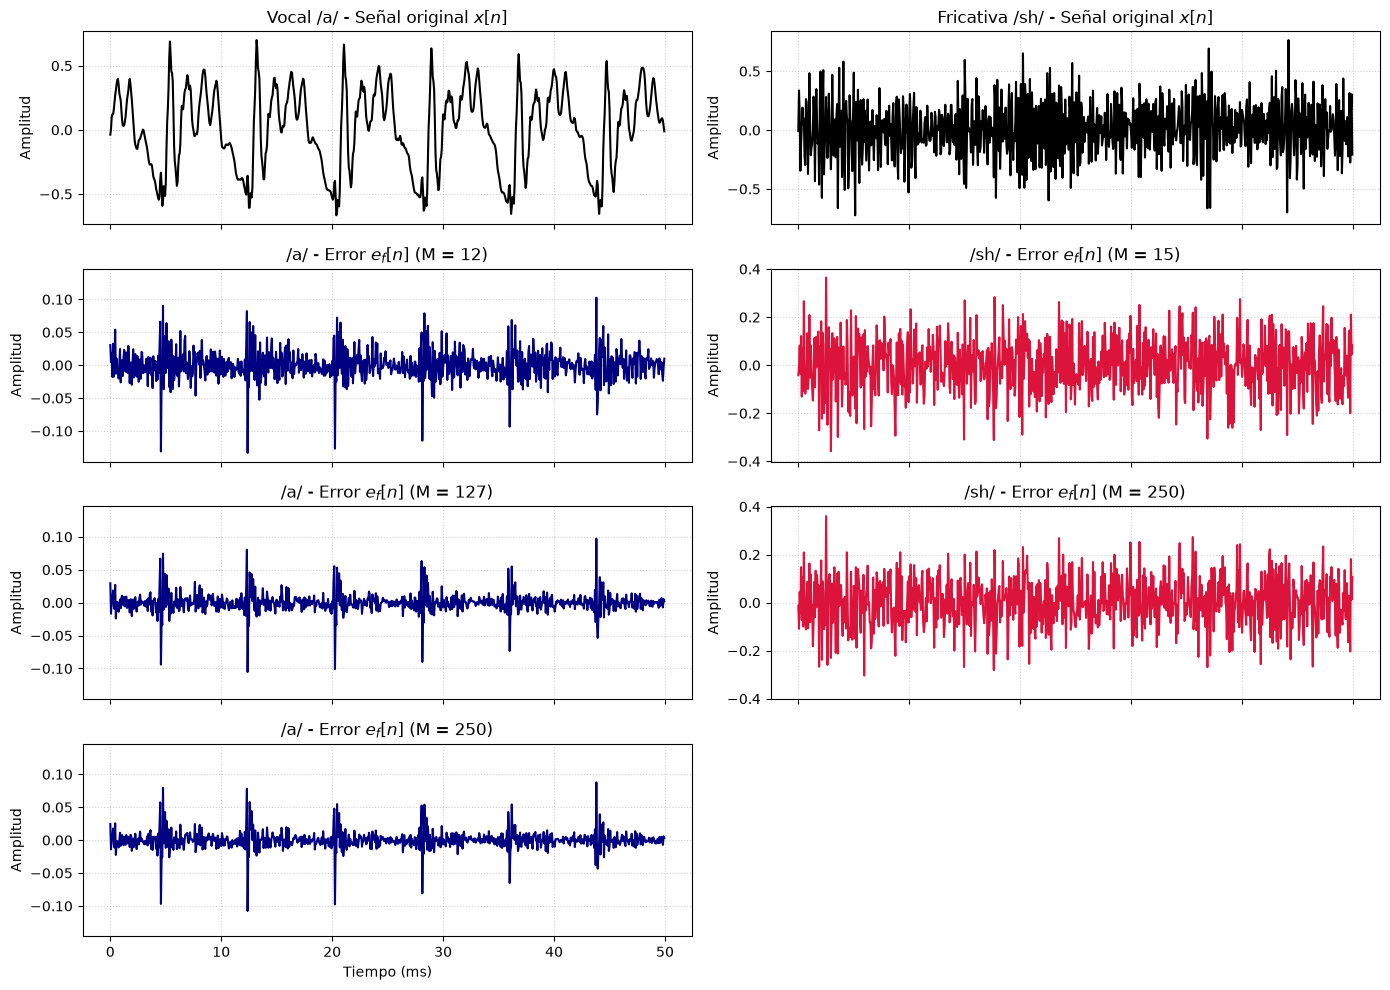

In [31]:
#estableciendo variables
fs = 16000
start_sample_sh = 20000 # escogiendo un punto lejos del inicio asi el audio es estable
start_sample_a = 40000 # en el audio que grabamos al principio hay mucho silencio
longitud = 800
tiempo = np.arange(longitud) / fs * 1000 #ms

# Esocgiendo diferentes M para el ruido /a/ para ver como cambia la señal de error dependiendo del codod
M_a_primer_codo = 12
M_a_segundo_codo = 127

# Lo mismo para /sh/
M_sh_primer_codo = 15

#ahora un M donde el error es mínimo para ambas señales
M_minimo = 250

# calculando la señal de error para /a/ con diferentes M
e_a_primer_codo = calcular_señal_de_error(a, M_a_primer_codo)
e_a_segundo_codo = calcular_señal_de_error(a, M_a_segundo_codo)
e_a_minimo = calcular_señal_de_error(a, M_minimo)

#recortando la señal para graficar
e_a_primer_codo = e_a_primer_codo[start_sample_a:start_sample_a + longitud]
e_a_segundo_codo = e_a_segundo_codo[start_sample_a:start_sample_a + longitud]
e_a_minimo = e_a_minimo[start_sample_a:start_sample_a + longitud]

# ahora haciendo lo mismo con la señal a_sh
e_sh_primer_codo = calcular_señal_de_error(sh, M_sh_primer_codo)
e_sh_minimo = calcular_señal_de_error(sh, M_minimo)

#de nuevo recortando la señal para graficar
e_sh_primer_codo = e_sh_primer_codo[start_sample_sh:start_sample_sh + longitud]
e_sh_minimo = e_sh_minimo[start_sample_sh:start_sample_sh + longitud]

#escogiendo el tramo de audio para graficar
a_tramo = a[start_sample_a:start_sample_a + longitud]
sh_tramo = sh[start_sample_sh:start_sample_sh + longitud]

# graficando todo 
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)

# Columna de /a/
errores_a = [(M_a_primer_codo, e_a_primer_codo),
             (M_a_segundo_codo, e_a_segundo_codo),
             (M_minimo, e_a_minimo)]

axes[0, 0].plot(tiempo, a_tramo, color="black")
axes[0, 0].set_title("Vocal /a/ - Señal original $x[n]$")

for i, (M_i, e) in enumerate(errores_a):
    axes[i + 1, 0].plot(tiempo, e, color="navy")
    axes[i + 1, 0].set_title(f"/a/ - Error $e_f[n]$ (M = {M_i})")

# Columna de /sh/
errores_sh = [(M_sh_primer_codo, e_sh_primer_codo),
              (M_minimo, e_sh_minimo)]

axes[0, 1].plot(tiempo, sh_tramo, color="black")
axes[0, 1].set_title("Fricativa /sh/ - Señal original $x[n]$")

for i, (M_i, e) in enumerate(errores_sh):
    axes[i + 1, 1].plot(tiempo, e, color="crimson")
    axes[i + 1, 1].set_title(f"/sh/ - Error $e_f[n]$ (M = {M_i})")

# Mismo rango vertical para los tres errores de cada columna (así se compara la amplitud)
for col, errores in enumerate([errores_a, errores_sh]):
    ymax = max(np.max(np.abs(e)) for _, e in errores)
    for fila in range(1, 4):
        axes[fila, col].set_ylim(-1.1 * ymax, 1.1 * ymax)

for ax in axes.flatten():
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.set_ylabel("Amplitud")

axes[-1, 0].set_xlabel("Tiempo (ms)")
axes[-1, 1].set_xlabel("Tiempo (ms)")

axes[3, 1].axis("off")

plt.tight_layout()
plt.show()

Ahora graficando la autocorelaccion de la señal /a/ para ver si hay alguna correlacion en lags mas altos que no puede aprovechar el fltro cuando su orden es muy bajo. 

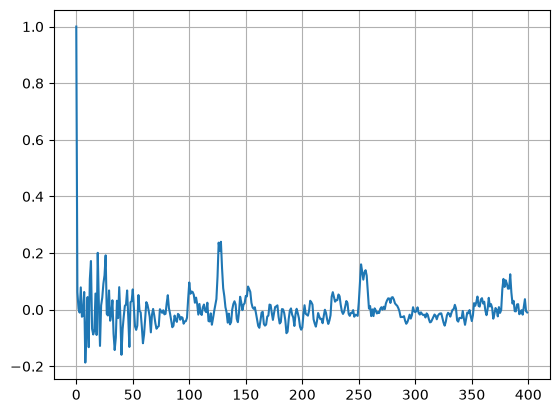

In [27]:
# graficando la autocrelación de la señal de error para /a/ con M = 12

e = calcular_señal_de_error(a, 12)[12:]     # sin el transitorio
e = e - np.mean(e)
r_e = correlate(e, e, mode="full", method="fft")
r_e = r_e[len(e)-1 : len(e)-1+400]
r_e = r_e / r_e[0]
plt.plot(r_e); plt.grid(); plt.show()

## Interpretación de los resultados

Primero de todo se puede ver que la señal de error tiene energía en los mismos lugares en que la señal original tiene ruido. Esto tiene todo el sentido del mundo, ya que los tramos donde la señal tiene más energía es donde el filtro se puede equivocar más, entonces el error también es más grande. Igualmente es interesante notar como mínimo para asegurar que la función que calcula el error genera resultados esperados.

Para /a/ se observan dos cambios de pendiente. El primero aparece para órdenes bajos, aproximadamente en la zona $M \approx 10$–$20$. Este primer codo está asociado a la correlación de corto plazo de la voz: con unos pocos coeficientes el predictor empieza a modelar la forma espectral introducida por el tracto vocal y sus resonancias.

Fijándonos en la señal de error para este valor de $M$ se puede ver cómo es un tren de pulsos separado por unos 7,8 ms. También se puede notar cómo la magnitud de estos pulsos es bastante alta y además hay mucha variación notable entre los pulsos, entonces sigue habiendo mucho error.

Más adelante aparece un segundo cambio, aproximadamente alrededor de $M \approx 110$–$130$. La vocal /a/ es periódica, por lo que una muestra se parece a otra situada aproximadamente un periodo de pitch antes. Cuando $M$ alcanza ese retardo, el predictor puede aprovechar esa periodicidad y el MSE vuelve a reducirse de forma leve pero visible en dB.

La señal de error para este valor de $M$ refleja esto, ya que los pulsos que se podían ver anteriormente tienen una magnitud mucho más pequeña, y también el ruido entre los pulsos también se redujo por mucho.

Esto se puede ver claramente en la señal de autocorrelación graficada justo antes de esta sección (para M = 12). Se puede ver cómo hay un pico cuando el lag tiene un valor de alrededor de 127 (también se pueden ver los armónicos), que es exactamente cuando el segundo codo ocurre. Esta vocal es periódica, entonces tiene autocorrelación que el filtro puede utilizar, pero solo si el orden del filtro es suficientemente grande. Entonces cuando el orden del filtro aumenta para poder incluir toda la autocorrelación presente en lags anteriores, entonces ahí es cuando el error se puede reducir de vuelta, y en turno cuando la función de error tiene el segundo codo.

$$N_0 \approx \frac{f_s}{f_0}$$

Si el segundo codo se sitúa cerca de $M \approx 127$ y $f_s = 16\,000$ Hz, la frecuencia fundamental asociada sería aproximadamente $f_0 \approx 16\,000/127 \approx 126$ Hz, un valor razonable para una voz sostenida.

Wikipedia (https://en.wikipedia.org/wiki/Voice_frequency) dice que "the voiced speech of a typical adult male will have a fundamental frequency from 90 to 155 Hz", y nuestra grabación es de un hombre, entonces tiene todo el sentido del mundo. No nos fiamos de Wikipedia por completo, entonces averiguamos un poco más y un artículo de la Biblioteca Nacional de Medicina del gobierno americano (https://pmc.ncbi.nlm.nih.gov/articles/PMC8478519/) dice que los hombres tienen un rango de "78 to 182 Hz", que también justifica el valor que calculamos.

Para /sh/ se observa principalmente un único codo en órdenes bajos. Esto concuerda con que /sh/ es un sonido no sonoro: no existe una vibración periódica clara de las cuerdas vocales y, por tanto, no aparece un segundo codo asociado a un periodo de pitch.

También fijándonos en la señal de error se puede ver cómo no hay ningún tipo de pulsos ni nada, se parece bastante al ruido. Entonces no hay ningún tipo de periodicidad que explique esta señal y que en turno pueda aprovechar el filtro para reducir el error.

# Parte 3 (Respuesta en frecuencia del filtro del error de predicción)

El tercer ejercicio utiliza los coeficientes obtenidos por el predictor, pero no pide representar el predictor directamente. Pide representar el filtro que genera el error de predicción.

## Predictor frente a filtro del error

El predictor calcula una estimación de $x[n]$:

$$\hat{x}[n] = a_1 x[n-1] + a_2 x[n-2] + \cdots + a_M x[n-M]$$

Como $e_f[n] = x[n] - \hat{x}[n]$, podemos escribir:

$$e_f[n] = x[n] - a_1 x[n-1] - a_2 x[n-2] - \cdots - a_M x[n-M]$$

Esto equivale a pasar $x[n]$ por un filtro FIR cuyos coeficientes son:

$$\bar{\mathbf{a}} = [1,\ -a_1,\ -a_2,\ \dots,\ -a_M]$$

Éste es el filtro del error de predicción. Su función es eliminar de la voz aquello que el predictor considera predecible. Por eso su salida es precisamente $e_f[n]$.

$$x[n] \;\longrightarrow\; \boxed{A(z)} \;\longrightarrow\; e_f[n]$$

## Por qué se representa $H(e^{j\omega})$

La respuesta en frecuencia indica qué frecuencias atenúa o deja pasar el filtro del error. Si la voz tiene una resonancia fuerte y muy predecible en cierta zona, el filtro tiende a crear un valle alrededor de esa frecuencia para eliminarla del residual. El objetivo ideal es que el error conserve poca estructura y se parezca más a ruido.

El ejercicio pide repetir este cálculo para $M = 1, 2, 4, 8, 16, 32$ y $64$. Así se ve cómo aumenta la capacidad del filtro para modelar la señal a medida que aumenta su orden.

C:\Users\elisa\AppData\Local\Temp\ipykernel_14580\1705536581.py:14: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, x = wavfile.read(nombre)


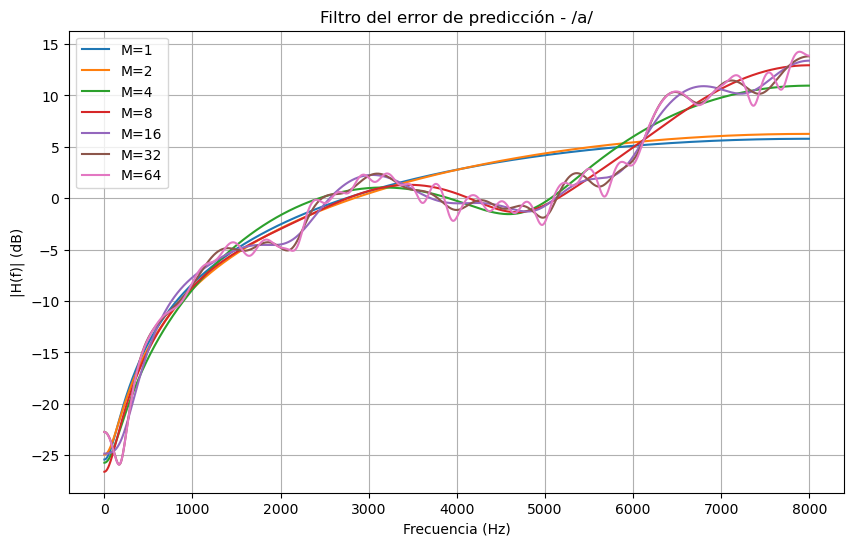

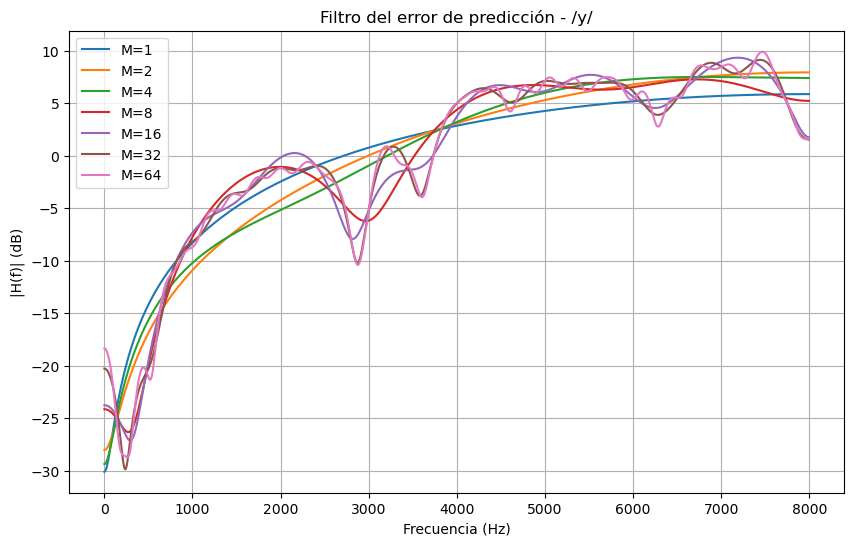

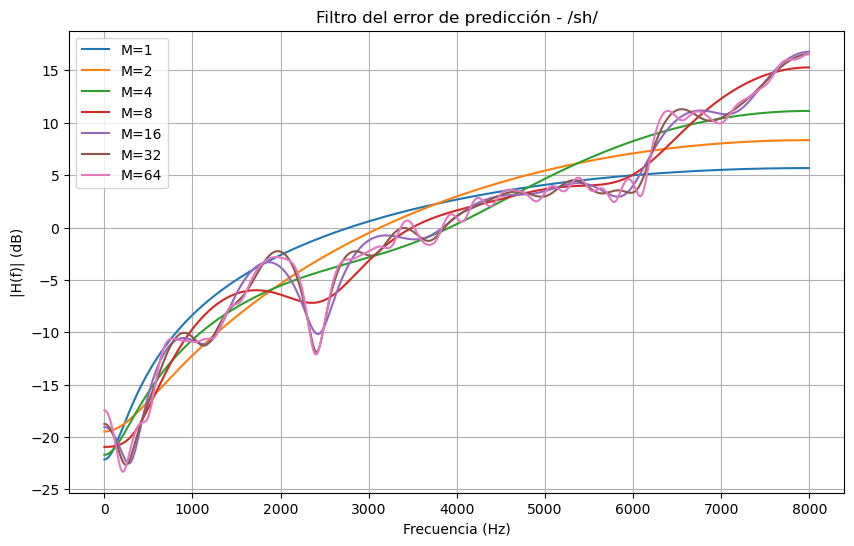

In [ ]:
# LEER AUDIO

def leer_audio(nombre):

    fs, x = wavfile.read(nombre)

    # Si es estéreo, pasar a mono
    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x.astype(float)

    # Pasar a 16 kHz si hace falta
    if fs != 16000:
        x = resample_poly(x, 16000, fs)
        fs = 16000

    # Usar 1 segundo
    x = x[:16000]

    # Quitar media
    x = x - np.mean(x)

    # Normalizar
    x = x / np.max(np.abs(x))

    return x, fs



# CALCULAR COEFICIENTES DEL PREDICTOR


def predictor(x, M):

    N = len(x)

    # autocorrelación
    r = np.correlate(x, x, mode="full")

    r = r[N-1:N+M] / N

    # Matriz R
    R = toeplitz(r[:M])

    # Vector p
    p = r[1:M+1]

    # coeficientes óptimos
    a = np.linalg.solve(R, p)

    return a



# VALORES DE M

valores_M = [1, 2, 4, 8, 16, 32, 64]



# AUDIO /a/

x, fs = leer_audio("A.wav")

plt.figure(figsize=(10,6))

for M in valores_M:

    a = predictor(x, M)

    # FILTRO DEL ERROR
    filtro_error = np.concatenate(([1], -a))

    f, H = freqz(filtro_error,worN=2048,fs=fs)

    plt.plot( f,20*np.log10(np.abs(H) + 1e-12),label=f"M={M}")


plt.xlabel("Frecuencia (Hz)")
plt.ylabel("|H(f)| (dB)")
plt.title("Filtro del error de predicción - /a/")
plt.legend()
plt.grid()
plt.show()

#AUDIO Y

x, fs = leer_audio("Y.wav")

plt.figure(figsize=(10,6))

for M in valores_M:

    a = predictor(x, M)

    filtro_error = np.concatenate(([1], -a))

    f, H = freqz(filtro_error,worN=2048,fs=fs)

    plt.plot(f,20*np.log10(np.abs(H) + 1e-12),label=f"M={M}")

plt.xlabel("Frecuencia (Hz)")
plt.ylabel("|H(f)| (dB)")
plt.title("Filtro del error de predicción - /y/")
plt.legend()
plt.grid()
plt.show()

#AUDIO SH

x, fs = leer_audio("SH.wav")

plt.figure(figsize=(10,6))

for M in valores_M:

    a = predictor(x, M)

    filtro_error = np.concatenate(([1], -a))

    f, H = freqz(filtro_error, worN=2048,fs=fs)

    plt.plot(f, 20*np.log10(np.abs(H) + 1e-12), label=f"M={M}")


plt.xlabel("Frecuencia (Hz)")
plt.ylabel("|H(f)| (dB)")
plt.title("Filtro del error de predicción - /sh/")
plt.legend()
plt.grid()
plt.show()

## Interpretación de las curvas

Para órdenes muy bajos, como $M = 1$ o $M = 2$, el filtro sólo puede describir una tendencia espectral muy simple. Las curvas son suaves porque hay pocos coeficientes disponibles.

Al pasar a $M = 4, 8, 16, 32$ y $64$ aparecen valles y variaciones más definidos. Esto significa que el filtro está aprendiendo más detalles de la estructura espectral de cada fonema y eliminando de la salida aquellas componentes que son más predecibles.

En /a/ y /y/, que son sonidos sonoros, la respuesta se vuelve progresivamente más detallada porque existe una estructura espectral y temporal importante. En /sh/ también se modela su coloración espectral, pero no aparece una periodicidad de pitch tan marcada, ya que es un sonido no sonoro.

La relación con $J(M)$ es directa: mientras aumentar $M$ produce una caída apreciable de $J$, el nuevo orden está explicando estructura adicional. Cuando $J(M)$ empieza a aplanarse, aumentar el orden modifica detalles cada vez más finos de $H(e^{j\omega})$ pero aporta una mejora pequeña en el error total.

# Parte 4 (Comparado grabacion real con grabacion simulada)

Primero de todo, generando una función que te calcule los coeficientes y error del filtro y que tome la señal y el orden como entrada.

In [28]:
def calcular_predictor(x, M):
    N = len(x)

    # autocorrelación
    r = np.correlate(x, x, mode="full")
    r = r[N-1:N+M] / N

    a = solve_toeplitz(r[:M], r[1:M+1])
    J = r[0] - np.dot(r[1:M+1], a)

    return a, J

Cargando los audios de vuelta, para asegurar que los audios que estamos analizando aquí no han sido cambiados. En teoría no tendría que haber cambiado nada, pero igualmente está bien incluirlo aquí al lado para no tener que preocuparnos de que estas variables cambiaron anteriormente y tener que fijarnos en todo el código.

In [ ]:
# CARGAR /a/ Y /sh/
a = cargar_audio("a_16k.wav", duracion=None)
sh = cargar_audio("sh_16k.wav", duracion=None)

C:\Users\itoma\AppData\Local\Temp\ipykernel_23512\1087720810.py:5: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, x = wavfile.read(nombre)


## Explicación del código

Primero de todo hay valores de $M$ diferentes dependiendo de la señal que estemos analizando. La consigna pide utilizar un valor de $M$ donde termine el primer codo. Estos valores ya se encontraron en el punto 2, donde analizamos el error como función de $M$ y encontramos los valores de $M$ para los codos de /a/ y /sh/.

Después, para escoger la excitación para usar nos podemos fijar en las señales de error que se graficaron en el punto 2.

Como se puede ver, el error para la señal /a/ es un tren de impulsos con un período de alrededor de 127 (esto también se discutió en el punto 2). También se tiene que definir la amplitud de cada impulso. Hay que asegurar que la energía por muestra sea $J$, y como hay un impulso cada 127 muestras y cada uno aporta $g^2$:

$$\frac{g^2}{N_0} = J$$

Entonces:

$$g = \sqrt{J \cdot N_0}$$

En cambio la señal de error para el /sh/ es básicamente ruido (fijarse en el gráfico del punto 2), entonces se puede modelar como ruido blanco gaussiano escalado para que su varianza sea $J$.

Después de esto el código simplemente utiliza la inversa del filtro para producir la señal desde las excitaciones artificiales que creamos en el código.

In [ ]:
# definiendo variables
M_a = 12
M_sh = 15
n0 = 127

N_a = len(a)
N_sh = len(sh)

# Calculando los coeficientes del predictor y el MSE mínimo J para /a/ y /sh/
a_coef, J_a_pred = calcular_predictor(a, M_a)
sh_coef, J_sh_pred = calcular_predictor(sh, M_sh)

g = np.sqrt(J_a_pred * n0) 
h = np.sqrt(J_sh_pred) 

#creando las señales de excitacion
a_exc = np.zeros(N_a)
a_exc[::n0] = g  # un impulso de amplitud g cada n0 muestras
sh_exc = np.random.randn(N_sh) * h

# chequeo: la energía por muestra de la excitación tiene que ser parecida a J
print(np.mean(a_exc**2), J_a_pred)
print(np.mean(sh_exc**2), J_sh_pred)

#ahora utilizando los coeficientes del predictor en inversa para producir la señal sintetizada
a_sint = lfilter([1], np.concatenate(([1], -a_coef)), a_exc)
sh_sint = lfilter([1], np.concatenate(([1], -sh_coef)), sh_exc)

# chequeo: la potencia de la señal sintetizada tiene que ser parecida a la original
print(np.mean(a_sint**2), np.mean(a**2))
print(np.mean(sh_sint**2), np.mean(sh**2))

# guardando los audios (normalizados para que no haya clipping)
def guardar_audio(nombre, y):
    y = y / np.max(np.abs(y))
    wavfile.write(nombre, fs, (y * 32767).astype(np.int16))

guardar_audio("a_sintetizada.wav", a_sint)
guardar_audio("sh_sintetizada.wav", sh_sint)

5.311316268585334e-05 5.3088486790628386e-05
0.007022766286918921 0.006998388025349873
0.024375772564852453 0.024416493798763157
0.02636325323978089 0.026331919033733688


## Discusión de Resultados

Comparado la grabación generada y la grabación real de /a/ se puede escuchar cómo la versión sintetizada es muy robótica comparada a la grabación original. Esto es debido a que literalmente solo consideramos los impulsos, y no el ruido que también hay entre impulsos y todas las otras imperfecciones de la grabación, entonces toda la parte "natural" de la grabación desaparece y solo notamos la información del tracto vocal de la /a/.

Específicamente se perdieron varias cosas cuando creamos nuestra propia excitación y no utilizamos el error exacto.

Primero de todo, estuvimos averiguando y aparentemente la voz humana tiene jitter, que significa que el período cambia levemente entre ciclos (https://speechprocessingbook.aalto.fi/representations/jitter-and-shimmer). En cambio, la voz que generamos nosotros con el filtro inverso no tiene nada de esto, ya que utilizamos un período constante durante toda la realización.

Otra característica del error creado por la voz humana es que los picos no tienen todos exactamente la misma amplitud, sino que van variando, y esto es conocido como shimmer (https://speechprocessingbook.aalto.fi/representations/jitter-and-shimmer).

Finalmente, también asumimos un modelo constante durante toda la duración de la grabación que es imposible que un humano mantenga un mismo "tono" perfecto durante un tiempo prolongado.

Igualmente, es sorprendente lo similar que es esta versión sintetizada a una /a/, ya que claramente se puede identificar esta vocal.

En cambio, como el error de la señal de /sh/ era simplemente ruido blanco, la señal sintetizada también se parecía a ruido blanco y no se podía discernir ningún ruido en particular.

## Modificando el modelo

Después de averiguar un poco más sobre la voz humana y aprender sobre conceptos como shimmer y jitter, intentamos generar un programa que medio randomize el período y las amplitudes del impulso (pero dentro de un cierto rango) para intentar crear una /a/ un poco más humana. También añadimos un poco de ruido entre pulsos, ya que como dijimos en la explicación anterior no son pulsos sino que también hay ruido aleatorio.

In [36]:
# definiendo variables
M_a = 12
n0 = 127

jitter = 0.02  # variación del período entre pulsos (desvío estándar, como fracción de n0)
shimmer = 0.2  # variación de la amplitud de cada pulso (desvío estándar, como fracción de g)
ruido_rel = 0.1  # fracción de la energía de la excitación que se le da al ruido

N_a = len(a)
rng = np.random.default_rng(0)  # semilla fija para que los resultados se puedan repetir

# Calculando los coeficientes del predictor y el MSE mínimo J para /a/
a_coef, J_a_pred = calcular_predictor(a, M_a)

g = np.sqrt(J_a_pred * (1 - ruido_rel) * n0)  # amplitud base de cada impulso

#creando la excitacion: impulsos con jitter y shimmer
impulsos = np.zeros(N_a)
pos = 0.0
while pos < N_a:
    impulsos[int(pos)] = g * (1 + shimmer * rng.standard_normal())  # amplitud variable
    pos += n0 * (1 + jitter * rng.standard_normal())  # período variable

# ajustando la energía de los impulsos para que coincida con la parte de J que les corresponde
impulsos *= np.sqrt(J_a_pred * (1 - ruido_rel) / np.mean(impulsos**2))

# ruido blanco gaussiano de fondo
ruido = rng.standard_normal(N_a) * np.sqrt(J_a_pred * ruido_rel)

a_exc_humana = impulsos + ruido

# chequeo: la energía por muestra de la excitación tiene que ser parecida a J
print(np.mean(a_exc_humana**2), J_a_pred)

#ahora utilizando los coeficientes del predictor en inversa para producir la señal sintetizada
a_sint_humana = lfilter([1], np.concatenate(([1], -a_coef)), a_exc_humana)

# chequeo: la potencia de la señal sintetizada tiene que ser parecida a la original
print(np.mean(a_sint_humana**2), np.mean(a**2))

# guardando el audio (usa la función guardar_audio de antes)
guardar_audio("a_sintetizada_humana.wav", a_sint_humana)

5.3140236444258306e-05 5.3088486790628386e-05
0.024452990538581066 0.024416493798763157


Estuvimos probando diferentes valores de jitter, shimmer y ruido generado y realmente se puede escuchar una diferencia, ya que no suena tan robótica y desagradable la voz sintetizada. Igualmente, sigue sonando muy robótica y no tiene nada que ver con una voz humana real, ya que con un error hecho con funciones matemáticas relativamente simples es imposible capturar el error exacto para recrear la voz humana y que suene natural.

# Parte 5 (Grabacion Sintetizada)

In [9]:
# Cargando el audio de voz libre
grab_libre = cargar_audio("long_rec_16k.wav", duracion=None)  # duracion=None para no limitar la duración

# Definiendo los parametros
fs = 16000
L = int(0.05 * fs) 
hop = L // 2  # cuanto avanza la ventana de bloque a bloque 
M = 12
P = fs // 160  # Período (pero en samples no por segundos)
N = len(grab_libre)  # x = tu grabación larga (aca hace falta incluir la señal de largo N, pero SE TIENE QUE GRABAR)
cantidad_bloques = (N - L) // hop + 1 # Cantidad de bloques que entran en la señal de largo N

# creando el tren de impulsos fuera del bucle
tren_impulsos = np.zeros(N)
tren_impulsos[::P] = 1  
y = np.zeros(N) # variable para señal sintetizada

# Trabajando bloque a bloque
for i in range(cantidad_bloques):
    bloque = grab_libre[i * hop:i * hop + L]
    bloque_modificado = bloque * np.hanning(L)  # Aplicando ventana de Hanning
    r = np.array([np.dot(bloque_modificado[:L-k], bloque_modificado[k:]) for k in range(M+1)]) # calcula la auto a mano (basatante ineficiente, pero para 12 lags funciona bien)
    coeficientes = solve_toeplitz(r[:M], r[1:M+1])

    # Filtrando el tren de impulsos con los coeficientes obtenidos
    filtro_error = np.concatenate(([1], -coeficientes))
    excitacion = tren_impulsos[i * hop:i * hop + L]
    bloque_sintetido = lfilter([1], filtro_error, excitacion)
    bloque_sintetido *= np.hanning(L)
    y[i * hop:i * hop + L] += bloque_sintetido

# Normalizando la señal sintetizada
y /= np.max(np.abs(y))

# Guardando la señal sintetizada
wavfile.write("voz_sintetizada.wav", fs, (y * 32767).astype(np.int16))

C:\Users\itoma\AppData\Local\Temp\ipykernel_24868\1087720810.py:5: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, x = wavfile.read(nombre)


## Comparación de la señal grabada con la señal sintetizada

La diferencia mas grande es que la señal sintentizada tiene un volumen mucho mas bajo que la señal. Esto es debido a tres razones diferentes: 
1. **Los impulsos son muy picudos.** Normalizás por el pico máximo, y una señal excitada por impulsos tiene picos altos pero energía promedio (RMS) baja. Al dejar el pico en 1, el resto queda chico.
2. **La ganancia del filtro $1/A(z)$ cambia mucho de un bloque a otro.** Los bloques con resonancias fuertes (vocales) amplifican bastante, y los de silencio o ruido casi nada. Unos pocos bloques fijan el pico y el resto queda muy por debajo.
3. **Cada bloque recibe impulsos de amplitud 1**, sin importar si el original era fuerte o débil. La señal sintetizada pierde la información de nivel.